In [1]:
import numpy as np
import pandas as pd

In [3]:
df=pd.read_csv(r"/content/Churn_Modelling.csv")

In [4]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.shape

(10000, 14)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['Exited'].value_counts()

,count
Exited,
0,7963
1,2037


In [9]:
df['Geography'].value_counts()

,count
Geography,
France,5014
Germany,2509
Spain,2477


In [10]:
df['Gender'].value_counts()

,count
Gender,
Male,5457
Female,4543


In [11]:
df.drop(columns=['RowNumber','CustomerId','Surname'],inplace=True)#inplace=True->Data me parmanet change

In [12]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [13]:
df=pd.get_dummies(df,columns=['Geography','Gender'],drop_first=True)#False False->France

In [14]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,0,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,1,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,1,True,False,True


In [15]:
X=df.drop(columns=['Exited'])
y=df['Exited']

In [16]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=1)

In [17]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


In [18]:
y

,Exited
0,1
1,0
2,1
3,0
4,0
...,...
9995,0
9996,0
9997,1
9998,1


In [19]:
X_train.shape

(8000, 11)

In [20]:
X_test.shape

(2000, 11)

In [21]:
y_train.shape

(8000,)

In [22]:
y_test.shape

(2000,)

Scaling

In [23]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [24]:
X_train_scaled

array([[-0.23082038, -0.94449979, -0.70174202, ...,  1.71490137,
        -0.57273139,  0.91509065],
       [-0.25150912, -0.94449979, -0.35520275, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [-0.3963303 ,  0.77498705,  0.33787579, ...,  1.71490137,
        -0.57273139, -1.09278791],
       ...,
       [ 0.22433188,  0.58393295,  1.3774936 , ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 0.13123255,  0.01077067,  1.03095433, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 1.1656695 ,  0.29735181,  0.33787579, ...,  1.71490137,
        -0.57273139,  0.91509065]])

In [25]:
X_test_scaled

array([[-1.03768121,  0.77498705, -1.0482813 , ..., -0.58312392,
        -0.57273139,  0.91509065],
       [ 0.30708683, -0.46686456, -0.70174202, ..., -0.58312392,
        -0.57273139,  0.91509065],
       [-1.23422423,  0.29735181, -1.0482813 , ..., -0.58312392,
        -0.57273139, -1.09278791],
       ...,
       [-0.86182692, -0.46686456,  1.72403288, ..., -0.58312392,
         1.74601919,  0.91509065],
       [-0.30323097, -0.84897275, -1.0482813 , ...,  1.71490137,
        -0.57273139, -1.09278791],
       [ 0.04847759,  1.25262228,  1.3774936 , ...,  1.71490137,
        -0.57273139,  0.91509065]])

In [26]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [39]:
model=Sequential()
model.add(Dense(11,activation='relu',input_dim=11))#input and hidden layer
model.add(Dense(11,activation='relu'))
model.add(Dense(1,activation='sigmoid'))#output layer

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [40]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
model.compile(loss='binary_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [49]:
history=model.fit(X_train_scaled,y_train,epochs=500,validation_split=0.2)

Epoch 1/500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8727 - loss: 0.3037 - val_accuracy: 0.8569 - val_loss: 0.3552
Epoch 2/500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8744 - loss: 0.3030 - val_accuracy: 0.8531 - val_loss: 0.3531
Epoch 3/500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8725 - loss: 0.3036 - val_accuracy: 0.8606 - val_loss: 0.3496
Epoch 4/500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8756 - loss: 0.3029 - val_accuracy: 0.8544 - val_loss: 0.3568
Epoch 5/500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8744 - loss: 0.3027 - val_accuracy: 0.8537 - val_loss: 0.3599
Epoch 6/500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8736 - loss: 0.3038 - val_accuracy: 0.8525 - val_loss: 0.3537
Epoch 7/500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8747 - loss: 0.3039 - val_accuracy: 0.8581 - val_loss: 0.3564
Epoch 8/500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8759 - loss: 0.3038 - val_accu

In [43]:
model.layers[0].get_weights()

[array([[ 9.4360000e-01, -1.8991080e-01, -5.4736383e-02,  9.1014661e-02,
          1.3607173e-01,  1.0683273e-01, -9.6931085e-02,  1.5496927e-01,
          1.4956059e-02,  1.8368684e-01,  7.3429161e-01],
        [ 8.3936292e-01,  9.9256730e-01,  2.3149751e-01,  2.7027810e-02,
          2.2650407e-01, -7.1566564e-01, -4.7001585e-01,  3.6023638e-01,
         -1.0150077e+00,  2.3008707e-01,  1.4167115e-01],
        [-3.1190205e-01,  4.5573007e-02, -3.2977152e-01,  8.6909786e-02,
         -3.6174081e-02,  4.5141082e-02,  3.7232861e-01,  1.1163698e+00,
         -3.5426697e-01, -3.8232180e-01,  6.5167189e-02],
        [ 9.3025243e-01, -6.1077397e-02,  6.1218921e-02,  6.0350865e-01,
          1.3241117e+00, -3.2185307e-03, -6.2569487e-01, -8.6941123e-01,
          1.1336477e-01,  8.8794196e-01, -2.7790236e-01],
        [ 1.4585062e-03, -2.3141743e-01, -1.2202016e+00,  1.0615780e+00,
         -5.9905207e-01,  6.2070951e-02, -1.3532430e-01, -1.0426677e+00,
         -9.2450035e-01,  1.2836057e+0

In [44]:
model.layers[1].get_weights()#Weights and bais deta haai

[array([[-3.03378761e-01, -3.73460501e-01,  1.16730642e+00,
          2.62430729e-03, -8.37239146e-01,  2.90887386e-01,
          5.67400813e-01, -2.47416809e-01, -5.08009732e-01,
         -1.13492556e-01,  4.68994558e-01],
        [-2.98818201e-01, -2.17127860e-01,  4.60111231e-01,
          5.62636107e-02, -3.32150340e-01,  7.84900427e-01,
         -8.66429567e-01, -6.20787799e-01,  4.59743261e-01,
          7.47098565e-01, -3.86702627e-01],
        [ 7.86478341e-01,  7.56715775e-01, -3.14138979e-01,
          2.49361515e-01, -2.54399449e-01, -1.47549927e-01,
          3.60881895e-01, -5.92795372e-01,  2.26915121e-01,
         -3.01837474e-01,  5.66772282e-01],
        [ 5.34108281e-01,  6.86877072e-01,  5.78764200e-01,
          2.78181314e-01, -6.56530976e-01,  1.78310454e-01,
         -4.74913836e-01,  2.66207993e-01,  9.25283372e-01,
         -1.98364228e-01, -3.74863833e-01],
        [-2.25503370e-01,  3.44849616e-01, -6.97092652e-01,
         -2.39564061e+00,  5.83591521e-01,  

In [48]:
model.layers[2].get_weights()#Weights and bais deta haai

[array([[ 0.8702771 ],
        [ 1.6901568 ],
        [-0.79736197],
        [-1.5569075 ],
        [-1.3095521 ],
        [-0.34952876],
        [ 1.2967112 ],
        [-0.54777   ],
        [ 1.2302926 ],
        [-0.1818353 ],
        [-0.95017254]], dtype=float32),
 array([-0.2751923], dtype=float32)]

In [45]:
y_log=model.predict(X_test_scaled)
y_log

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


array([[0.02365522],
       [0.06725942],
       [0.02642023],
       ...,
       [0.00915579],
       [0.06453419],
       [0.48542026]], dtype=float32)

In [46]:
y_pred=np.where(y_log>0.5,1,0)#y_log>0.5 then 1 otherwise 0
y_pred

array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]])

In [47]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.8555

In [50]:
import matplotlib.pyplot as plt

In [53]:
history

In [52]:
history.history

{'accuracy': [0.8726562261581421,
  0.8743749856948853,
  0.8725000023841858,
  0.8756250143051147,
  0.8743749856948853,
  0.8735937476158142,
  0.8746874928474426,
  0.8759375214576721,
  0.8746874928474426,
  0.8767187595367432,
  0.875,
  0.8737499713897705,
  0.8756250143051147,
  0.8754687309265137,
  0.874218761920929,
  0.8767187595367432,
  0.8753125071525574,
  0.8743749856948853,
  0.8762500286102295,
  0.8748437762260437,
  0.8737499713897705,
  0.8764062523841858,
  0.8745312690734863,
  0.8734375238418579,
  0.8735937476158142,
  0.8737499713897705,
  0.8753125071525574,
  0.875781238079071,
  0.875,
  0.8748437762260437,
  0.875781238079071,
  0.8732812404632568,
  0.8731250166893005,
  0.8746874928474426,
  0.8764062523841858,
  0.875781238079071,
  0.874218761920929,
  0.8748437762260437,
  0.8779687285423279,
  0.8754687309265137,
  0.8746874928474426,
  0.8760937452316284,
  0.8764062523841858,
  0.8745312690734863,
  0.8759375214576721,
  0.8737499713897705,
  0.875

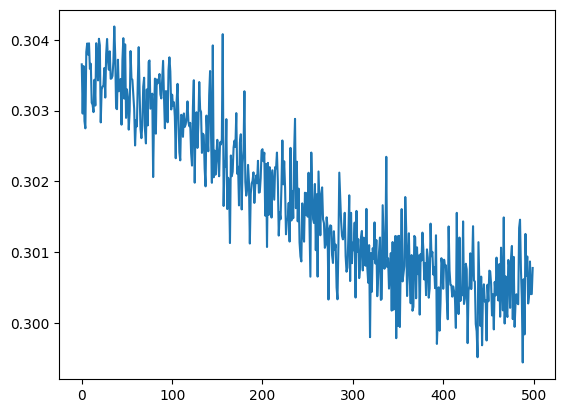

In [54]:
plt.plot(history.history['loss'])

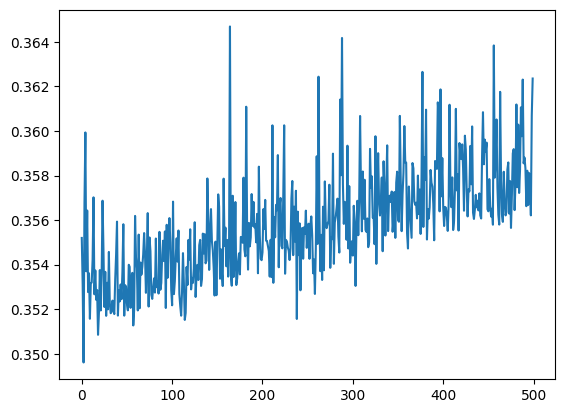

In [55]:
plt.plot(history.history['val_loss'])

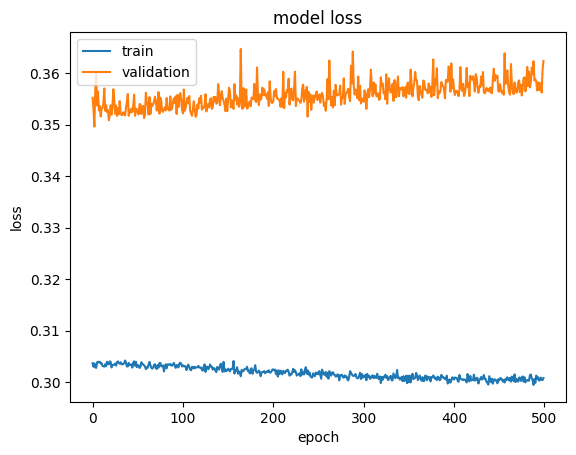

In [56]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','validation'],loc='upper left')

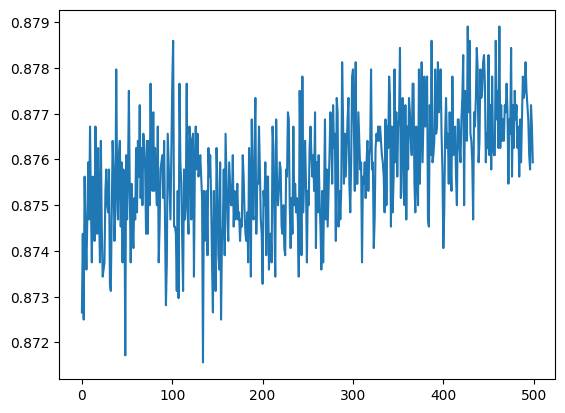

In [57]:
plt.plot(history.history['accuracy'])

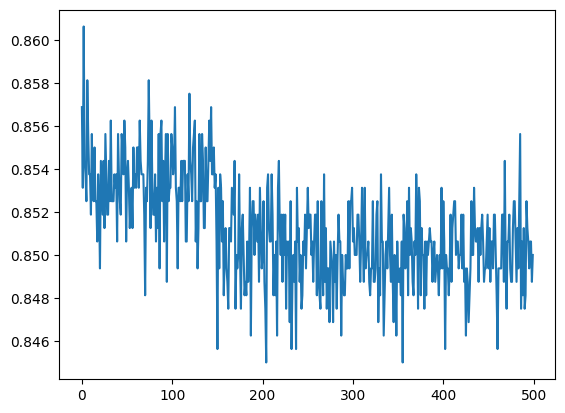

In [58]:
plt.plot(history.history['val_accuracy'])

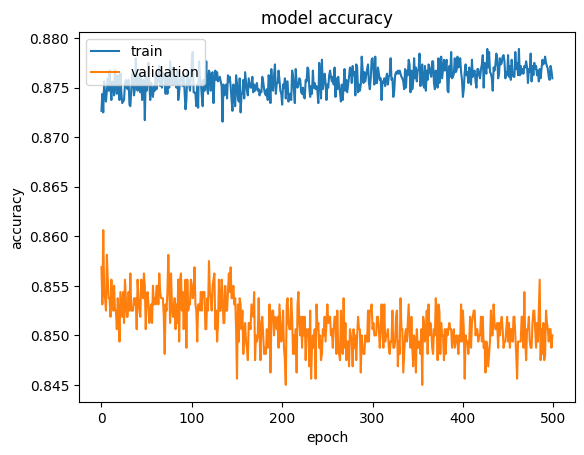

In [59]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','validation'],loc='upper left')